# Classificação de Espécies de Flores Iris utilizando Redes Neurais

## Projeto NP2 — Redes Neurais

### Objetivo

Desenvolver uma rede neural artificial capaz de classificar
espécies de flores do conjunto de dados Iris, utilizando
uma implementação própria dos algoritmos de propagação
direta (Forward Propagation), retropropagação do erro
(Backpropagation) e otimização por Gradiente Descendente
Estocástico (SGD).

### Espécies classificadas

- Iris-setosa
- Iris-versicolor
- Iris-virginica

### Tecnologias utilizadas

- Python
- NumPy
- Pandas
- Matplotlib
- Scikit-Learn (somente para pré-processamento e divisão dos dados)

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [44]:
import pandas as pd

# Caminho do dataset
caminho = "../dados/iris.csv"

# Nomes das colunas
colunas = [
    "comprimento_sepala",
    "largura_sepala",
    "comprimento_petala",
    "largura_petala",
    "especie"
]

# Carregamento ignorando o cabeçalho original
df = pd.read_csv(
    caminho,
    header=0,
    names=colunas
)

# Remover espaços dos nomes das espécies
df["especie"] = df["especie"].str.strip()

# Converter características para valores numéricos
caracteristicas = colunas[:4]

df[caracteristicas] = df[caracteristicas].apply(
    pd.to_numeric,
    errors="coerce"
)

# Remover possíveis linhas inválidas
df = df.dropna().reset_index(drop=True)

print("Dataset carregado e tratado!")
print("Dimensões:", df.shape)

Dataset carregado e tratado!
Dimensões: (150, 5)


## Análise inicial do conjunto de dados

O conjunto de dados Iris utilizado neste projeto possui 150
amostras, distribuídas igualmente entre três espécies:
Setosa, Versicolor e Virginica.

Cada amostra apresenta quatro características numéricas:
comprimento e largura da sépala, comprimento e largura da pétala.

Durante a verificação inicial, não foram identificados valores
ausentes. Foram encontrados três registros com medidas
duplicadas, que serão preservados nesta etapa, pois valores
iguais não comprovam que sejam observações incorretas.

A distribuição equilibrada das espécies é um aspecto positivo
para o desenvolvimento do classificador, pois evita que uma
classe tenha quantidade de exemplos muito superior às demais.

In [45]:
print("Dimensões:", df.shape)

print("\nPrimeiras amostras:")
display(df.head())

print("\nValores ausentes:")
print(df.isnull().sum())

print("\nRegistros duplicados:")
print(df.duplicated().sum())

print("\nDistribuição das espécies:")
print(df["especie"].value_counts())

Dimensões: (150, 5)

Primeiras amostras:


,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Valores ausentes:
comprimento_sepala    0
largura_sepala        0
comprimento_petala    0
largura_petala        0
especie               0
dtype: int64

Registros duplicados:
3

Distribuição das espécies:
especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [46]:
# Calcular a média das características para cada espécie
medias_especies = df.groupby("especie")[caracteristicas].mean()

display(medias_especies.round(2))

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala
especie,,,,
setosa,5.01,3.42,1.46,0.24
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


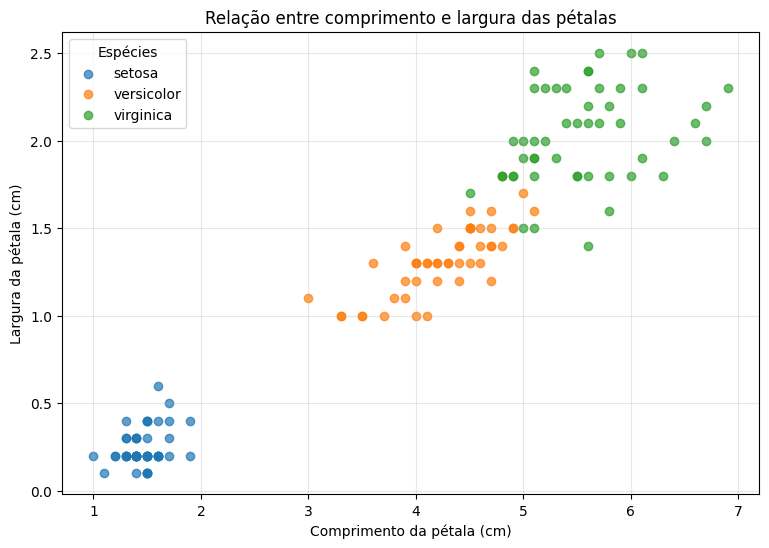

In [47]:
plt.figure(figsize=(9, 6))

for especie in df["especie"].unique():

    dados = df[df["especie"] == especie]

    plt.scatter(
        dados["comprimento_petala"],
        dados["largura_petala"],
        label=especie,
        alpha=0.7
    )

plt.title("Relação entre comprimento e largura das pétalas")
plt.xlabel("Comprimento da pétala (cm)")
plt.ylabel("Largura da pétala (cm)")
plt.legend(title="Espécies")
plt.grid(alpha=0.3)

plt.show()

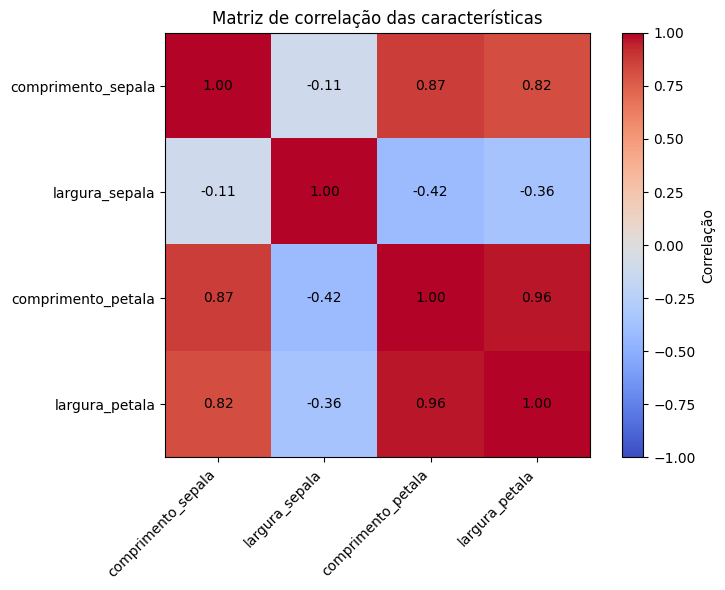

In [48]:
correlacao = df[caracteristicas].corr()

plt.figure(figsize=(8, 6))

plt.imshow(correlacao, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlação")

plt.xticks(
    range(len(caracteristicas)),
    caracteristicas,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(caracteristicas)),
    caracteristicas
)

for i in range(len(caracteristicas)):
    for j in range(len(caracteristicas)):
        plt.text(
            j, i,
            f"{correlacao.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Matriz de correlação das características")
plt.tight_layout()
plt.show()

## Análise das relações entre as características

A análise do gráfico de dispersão entre o comprimento e a largura das pétalas demonstrou diferenças entre as três espécies de flores Iris.

A espécie Setosa apresentou um agrupamento visualmente separado das demais, caracterizado por menores dimensões das pétalas. A espécie Versicolor apresentou valores intermediários, enquanto a Virginica apresentou, predominantemente, medidas maiores.

Entretanto, foi possível observar algumas regiões de sobreposição entre Versicolor e Virginica, indicando que a distinção entre essas duas espécies pode ser mais desafiadora.

A matriz de correlação também revelou relações importantes entre as características. Destaca-se a correlação positiva de 0,96 entre o comprimento e a largura das pétalas, indicando uma forte associação entre essas variáveis. Também foram observadas correlações positivas de 0,87 entre o comprimento da sépala e o comprimento da pétala, e de 0,82 entre o comprimento da sépala e a largura da pétala.

Esses resultados demonstram que as características analisadas apresentam diferentes níveis de associação e podem contribuir para a identificação das espécies. Portanto, as quatro variáveis serão inicialmente mantidas para a construção da rede neural.

In [49]:
# Estatísticas descritivas das características
display(df[caracteristicas].describe().round(2))

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


### Análise das estatísticas descritivas

A análise estatística das características do conjunto de dados Iris permitiu identificar diferenças nas escalas e na dispersão das variáveis.

O comprimento da sépala apresentou média de 5,84 cm e desvio padrão de 0,83. A largura da sépala apresentou média de 3,05 cm e menor dispersão entre as características, com desvio padrão de 0,43.

Em relação às pétalas, o comprimento apresentou média de 3,76 cm e desvio padrão de 1,76, enquanto a largura apresentou média de 1,20 cm e desvio padrão de 0,76.

Os resultados demonstram que as características possuem diferentes níveis de variação. Por esse motivo, será utilizada a padronização dos dados na etapa de pré-processamento, permitindo que as variáveis sejam apresentadas em escalas comparáveis para o treinamento da rede neural.

# Pré-processamento e preparação dos dados

Nesta etapa, os dados serão preparados para alimentar a rede
neural artificial. Serão realizadas a codificação das classes,
a divisão dos dados em treinamento, validação e teste e a
padronização das características numéricas.

In [50]:
# Codificação manual das espécies
mapeamento_especies = {
    "setosa": 0,
    "versicolor": 1,
    "virginica": 2
}

df["rotulo"] = df["especie"].map(mapeamento_especies)

# Separação entre características e variável-alvo
X = df[caracteristicas].values
y = df["rotulo"].values

print("Formato das características:", X.shape)
print("Formato dos rótulos:", y.shape)

print("\nMapeamento das espécies:")
print(mapeamento_especies)

Formato das características: (150, 4)
Formato dos rótulos: (150,)

Mapeamento das espécies:
{'setosa': 0, 'versicolor': 1, 'virginica': 2}


In [51]:
# Primeira divisão: treinamento (70%) e dados temporários (30%)
X_treino, X_temp, y_treino, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Segunda divisão: validação (15%) e teste (15%)
X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# Conferência das divisões
print("Amostras de treinamento:", len(X_treino))
print("Amostras de validação:", len(X_validacao))
print("Amostras de teste:", len(X_teste))

print("\nFormato dos conjuntos:")
print("Treinamento:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)

Amostras de treinamento: 105
Amostras de validação: 22
Amostras de teste: 23

Formato dos conjuntos:
Treinamento: (105, 4)
Validação: (22, 4)
Teste: (23, 4)


In [52]:
# Padronização das características
scaler = StandardScaler()

# Ajusta o padronizador somente com os dados de treinamento
X_treino = scaler.fit_transform(X_treino)

# Aplica a mesma transformação aos outros conjuntos
X_validacao = scaler.transform(X_validacao)
X_teste = scaler.transform(X_teste)

print("Dados padronizados com sucesso!")

Dados padronizados com sucesso!


In [53]:
print("RESUMO DA PREPARAÇÃO DOS DADOS")

print("\nTreinamento:")
print("X:", X_treino.shape)
print("y:", y_treino.shape)

print("\nValidação:")
print("X:", X_validacao.shape)
print("y:", y_validacao.shape)

print("\nTeste:")
print("X:", X_teste.shape)
print("y:", y_teste.shape)

print("\nClasses presentes:")
print(np.unique(y_treino))

RESUMO DA PREPARAÇÃO DOS DADOS

Treinamento:
X: (105, 4)
y: (105,)

Validação:
X: (22, 4)
y: (22,)

Teste:
X: (23, 4)
y: (23,)

Classes presentes:
[0 1 2]


# Construção da Rede Neural Artificial

## Arquitetura da MLP

Neste projeto será implementada uma rede neural artificial
do tipo Multilayer Perceptron (MLP), composta por uma camada
de entrada, uma camada oculta e uma camada de saída.

A camada de entrada receberá as quatro características
numéricas das flores Iris.

A camada oculta será composta por oito neurônios, utilizando
a função de ativação ReLU.

A camada de saída possuirá três neurônios, correspondentes
às três espécies classificadas, utilizando a função Softmax
para produzir probabilidades.

A função de perda utilizada será a Cross-Entropy, enquanto
a atualização dos parâmetros será realizada pelo método
Stochastic Gradient Descent (SGD).

In [ ]:
# Definição da arquitetura
n_entradas = 4
n_ocultos = 16
n_saidas = 3

# Inicialização do gerador aleatório
rng = np.random.default_rng(42)

# Inicialização dos pesos
W1 = rng.normal(
    0,
    np.sqrt(2 / n_entradas),
    size=(n_entradas, n_ocultos)
)

W2 = rng.normal(
    0,
    np.sqrt(1 / n_ocultos),
    size=(n_ocultos, n_saidas)
)

# Inicialização dos bias
b1 = np.zeros((1, n_ocultos))
b2 = np.zeros((1, n_saidas))

print("Parâmetros inicializados com sucesso!")

print("\nFormato dos pesos W1:", W1.shape)
print("Formato dos bias b1:", b1.shape)

print("\nFormato dos pesos W2:", W2.shape)
print("Formato dos bias b2:", b2.shape)

Parâmetros inicializados com sucesso!

Formato dos pesos W1: (4, 16)
Formato dos bias b1: (1, 16)

Formato dos pesos W2: (16, 3)
Formato dos bias b2: (1, 3)


In [55]:
print("Pesos da primeira camada:")
print(W1)

print("\nBias da primeira camada:")
print(b1)

print("\nPesos da segunda camada:")
print(W2)

print("\nBias da segunda camada:")
print(b2)

Pesos da primeira camada:
[[ 0.21546751 -0.73537981  0.53064913  0.66507969 -1.37959021 -0.92077996
   0.09039682 -0.22361728 -0.01188021 -0.60319315  0.62182827  0.54998195
   0.04669075  0.7970799   0.33057903 -0.60761153]
 [ 0.26074618 -0.67803239  0.62115816 -0.03530295 -0.13071743 -0.4814899
   0.86446727 -0.10926884 -0.30287351 -0.24899602  0.37639943  0.25840798
   0.29184603  0.30463645  1.51437354 -0.28737881]
 [-0.36221031 -0.57542421  0.43556323  0.79830396 -0.08057302 -0.59408034
  -0.58299626  0.46003857  0.52556006  0.38406807 -0.47058643  0.16416285
   0.08250933  0.15463619  0.6161932   0.15810593]
 [ 0.48006438  0.04778562  0.20443829  0.44638819 -1.03036476 -0.22604168
  -0.33260369 -0.45175486 -0.19455495  1.05708314 -0.61223505  0.68467619
  -1.18996863 -0.23679948  0.1150838   0.41452179]]

Bias da primeira camada:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

Pesos da segunda camada:
[[ 0.17780664  0.19833681 -0.08718127]
 [-0.11558795  0.21449397 -0.047826

In [56]:
print("Dimensões dos parâmetros:")

print("W1:", W1.shape)
print("b1:", b1.shape)

print("W2:", W2.shape)
print("b2:", b2.shape)

Dimensões dos parâmetros:
W1: (4, 16)
b1: (1, 16)
W2: (16, 3)
b2: (1, 3)


In [57]:
# Função de ativação ReLU
def relu(x):
    return np.maximum(0, x)


# Derivada da função ReLU
def relu_derivada(x):
    return (x > 0).astype(float)


print("Funções ReLU implementadas!")

Funções ReLU implementadas!


In [58]:
# Função Softmax
def softmax(x):
    x_estavel = x - np.max(x, axis=1, keepdims=True)

    exp_x = np.exp(x_estavel)

    return exp_x / np.sum(exp_x, axis=1, keepdims=True)


print("Função Softmax implementada!")

Função Softmax implementada!


In [59]:
def one_hot(y, numero_classes=3):
    matriz = np.zeros((len(y), numero_classes))

    matriz[np.arange(len(y)), y] = 1

    return matriz


print("Exemplo de codificação One-Hot:")
print(one_hot(np.array([0, 1, 2])))

Exemplo de codificação One-Hot:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


In [60]:
def cross_entropy(y_real, y_predito):
    epsilon = 1e-12

    y_predito = np.clip(
        y_predito,
        epsilon,
        1 - epsilon
    )

    perda = -np.sum(
        y_real * np.log(y_predito)
    ) / len(y_real)

    return perda


print("Função Cross-Entropy implementada!")

Função Cross-Entropy implementada!


In [61]:
def forward_propagation(X, W1, b1, W2, b2):
    # Primeira camada: entrada para camada oculta
    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)

    # Segunda camada: camada oculta para saída
    Z2 = np.dot(A1, W2) + b2
    A2 = softmax(Z2)

    # Armazena os valores intermediários para o backpropagation
    cache = {
        "X": X,
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "A2": A2
    }

    return A2, cache

In [62]:
# Seleciona as primeiras 5 amostras de treinamento
X_teste_forward = X_treino[:5]

# Executa a propagação direta
probabilidades, cache = forward_propagation(
    X_teste_forward, W1, b1, W2, b2
)

print("Probabilidades previstas:")
print(probabilidades)

print("\nSoma das probabilidades por amostra:")
print(np.sum(probabilidades, axis=1))

Probabilidades previstas:
[[0.13496771 0.57972659 0.2853057 ]
 [0.25211689 0.38854814 0.35933497]
 [0.12488454 0.62621337 0.24890208]
 [0.21876049 0.31030607 0.47093344]
 [0.27141072 0.38530936 0.34327993]]

Soma das probabilidades por amostra:
[1. 1. 1. 1. 1.]


In [63]:
def backpropagation(Y_real, cache, W2):
    # Recupera os valores da propagação direta
    X = cache["X"]
    Z1 = cache["Z1"]
    A1 = cache["A1"]
    A2 = cache["A2"]

    # Quantidade de amostras
    m = X.shape[0]

    # Gradientes da camada de saída
    dZ2 = (A2 - Y_real) / m
    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Gradientes da camada oculta
    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * relu_derivada(Z1)
    dW1 = np.dot(X.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [64]:
# Seleciona apenas uma amostra para demonstrar o SGD
Y_treino_exemplo = one_hot(y_treino[:1])

probabilidades, cache = forward_propagation(
    X_treino[:1], W1, b1, W2, b2
)

# Calcula os gradientes de uma única amostra
dW1, db1, dW2, db2 = backpropagation(
    Y_treino_exemplo, cache, W2
)

print("Dimensões dos gradientes:")
print("dW1:", dW1.shape)
print("db1:", db1.shape)
print("dW2:", dW2.shape)
print("db2:", db2.shape)

Dimensões dos gradientes:
dW1: (4, 16)
db1: (1, 16)
dW2: (16, 3)
db2: (1, 3)


In [65]:
def atualizar_parametros(W1, b1, W2, b2,
                         dW1, db1, dW2, db2,
                         taxa_aprendizado):

    W1 = W1 - taxa_aprendizado * dW1
    b1 = b1 - taxa_aprendizado * db1

    W2 = W2 - taxa_aprendizado * dW2
    b2 = b2 - taxa_aprendizado * db2

    return W1, b1, W2, b2

In [66]:
# Define a taxa de aprendizado
taxa_aprendizado = 0.01

# Criando cópias dos parâmetros originais
W1_teste = W1.copy()
b1_teste = b1.copy()
W2_teste = W2.copy()
b2_teste = b2.copy()

# Aplicando uma atualização SGD de demonstração
W1_teste, b1_teste, W2_teste, b2_teste = atualizar_parametros(
    W1_teste, b1_teste, W2_teste, b2_teste,
    dW1, db1, dW2, db2,
    taxa_aprendizado
)

print("Diferença nos pesos da primeira camada:")
print(np.sum(np.abs(W1_teste - W1)))

print("\nDiferença nos pesos da segunda camada:")
print(np.sum(np.abs(W2_teste - W2)))

Diferença nos pesos da primeira camada:
0.011984300401987917

Diferença nos pesos da segunda camada:
0.056248108094410124


In [67]:

def treinar_rede(
    X_treino, y_treino,
    X_validacao, y_validacao,
    W1, b1, W2, b2,
    epocas=1000,
    taxa_aprendizado=0.01
):
    historico_perda_treino = []
    historico_perda_validacao = []

    historico_acuracia_treino = []
    historico_acuracia_validacao = []

    # Novo histórico: perda de cada atualização SGD
    historico_perda_sgd = []

    gerador = np.random.default_rng(42)

    for epoca in range(epocas):

        indices = gerador.permutation(len(X_treino))

        # SGD: uma amostra por atualização
        for indice in indices:

            X_amostra = X_treino[indice:indice + 1]
            y_amostra = one_hot(y_treino[indice:indice + 1])

            # 1. Forward propagation
            probabilidades, cache = forward_propagation(
                X_amostra, W1, b1, W2, b2
            )

            # 2. Registra a perda individual
            perda_amostra = cross_entropy(
                y_amostra,
                probabilidades
            )

            historico_perda_sgd.append(perda_amostra)

            # 3. Backpropagation
            dW1, db1, dW2, db2 = backpropagation(
                y_amostra, cache, W2
            )

            # 4. Atualização dos parâmetros
            W1, b1, W2, b2 = atualizar_parametros(
                W1, b1, W2, b2,
                dW1, db1, dW2, db2,
                taxa_aprendizado
            )

        # Avaliação após cada época
        pred_treino, _ = forward_propagation(
            X_treino, W1, b1, W2, b2
        )

        pred_validacao, _ = forward_propagation(
            X_validacao, W1, b1, W2, b2
        )

        perda_treino = cross_entropy(
            one_hot(y_treino), pred_treino
        )

        perda_validacao = cross_entropy(
            one_hot(y_validacao), pred_validacao
        )

        acuracia_treino = np.mean(
            np.argmax(pred_treino, axis=1) == y_treino
        )

        acuracia_validacao = np.mean(
            np.argmax(pred_validacao, axis=1) == y_validacao
        )

        historico_perda_treino.append(perda_treino)
        historico_perda_validacao.append(perda_validacao)

        historico_acuracia_treino.append(acuracia_treino)
        historico_acuracia_validacao.append(acuracia_validacao)

    historico = {
        "perda_treino": historico_perda_treino,
        "perda_validacao": historico_perda_validacao,
        "acuracia_treino": historico_acuracia_treino,
        "acuracia_validacao": historico_acuracia_validacao,
        "perda_sgd": historico_perda_sgd
    }

    return W1, b1, W2, b2, historico


In [68]:
W1, b1, W2, b2, historico = treinar_rede(
    X_treino,
    y_treino,
    X_validacao,
    y_validacao,
    W1, b1, W2, b2,
    epocas=1000,
    taxa_aprendizado=0.01
    
)

print("Treinamento concluído!")

print("\nPerda final de treinamento:")
print(historico["perda_treino"][-1])

print("\nPerda final de validação:")
print(historico["perda_validacao"][-1])

print("\nAcurácia final de treinamento:")
print(historico["acuracia_treino"][-1])

print("\nAcurácia final de validação:")
print(historico["acuracia_validacao"][-1])

Treinamento concluído!

Perda final de treinamento:
0.00394338638195315

Perda final de validação:
0.3705952818131541

Acurácia final de treinamento:
1.0

Acurácia final de validação:
0.9545454545454546


### Análise da evolução da perda utilizando SGD

O gráfico apresenta a evolução da função de perda (Cross-Entropy) durante 1.000 épocas de treinamento, totalizando aproximadamente 105.000 atualizações dos parâmetros da rede neural.

Observa-se que, no início do treinamento, a perda apresenta oscilações acentuadas e valores elevados. Esse comportamento está relacionado à natureza estocástica do algoritmo SGD, que realiza atualizações dos pesos individualmente para cada amostra.

Ao longo do treinamento, percebe-se uma redução progressiva da magnitude das oscilações e da perda média, indicando que a rede está ajustando seus parâmetros para minimizar o erro de classificação.

A curva da média móvel permite visualizar essa tendência de maneira mais clara, demonstrando a redução geral da função de custo durante o processo de otimização.

Dessa forma, os resultados evidenciam o funcionamento do algoritmo Stochastic Gradient Descent e seu processo de convergência durante o treinamento.

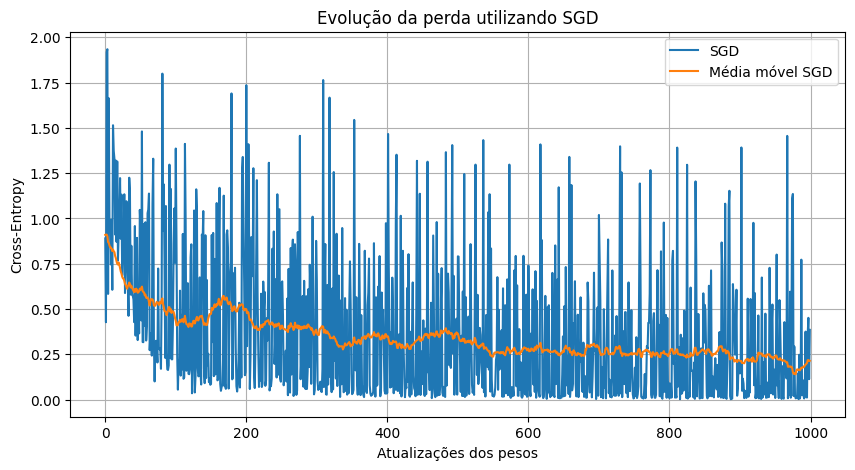

In [85]:

plt.figure(figsize=(10, 5))

plt.plot(
    historico["perda_sgd"][:1000],
    label="SGD"
)

janela = 50
media_movel = np.convolve(
    historico["perda_sgd"],
    np.ones(janela) / janela,
    mode="valid"
)

plt.plot(
    media_movel[:1000],
    label="Média móvel SGD"
)

plt.title("Evolução da perda utilizando SGD")
plt.xlabel("Atualizações dos pesos")
plt.ylabel("Cross-Entropy")
plt.legend()
plt.grid(True)
plt.show()


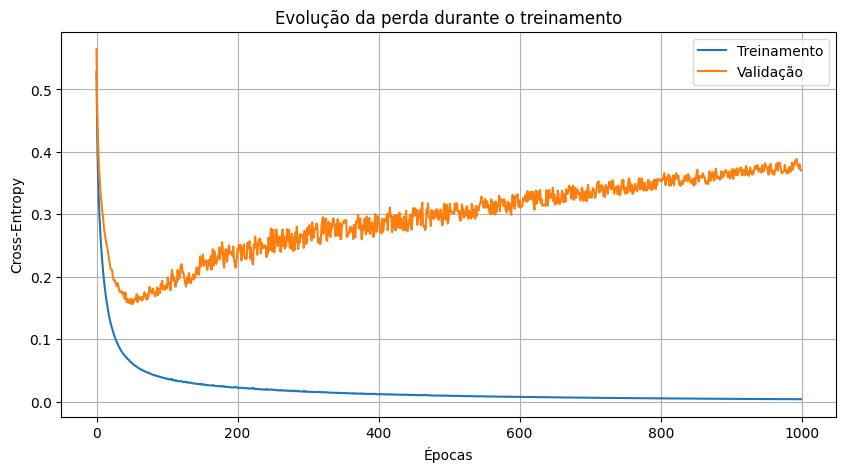

In [70]:
plt.figure(figsize=(10, 5))

plt.plot(
    historico["perda_treino"],
    label="Treinamento"
)

plt.plot(
    historico["perda_validacao"],
    label="Validação"
)

plt.title("Evolução da perda durante o treinamento")
plt.xlabel("Épocas")
plt.ylabel("Cross-Entropy")
plt.legend()
plt.grid(True)
plt.show()

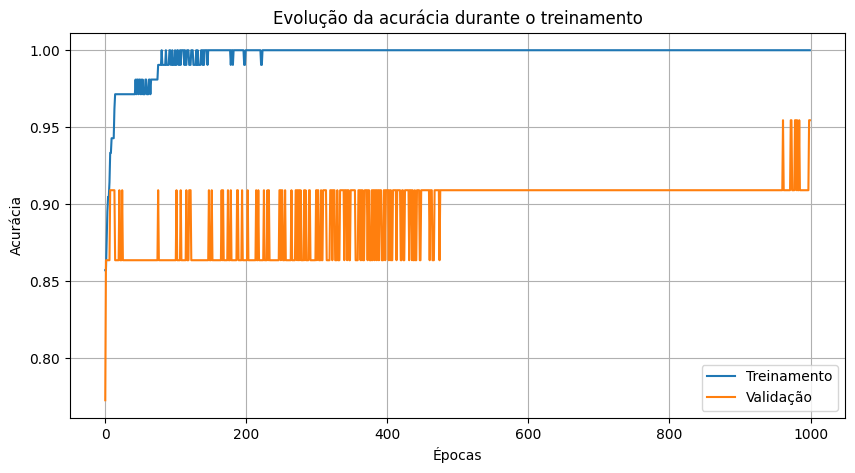

In [71]:
plt.figure(figsize=(10, 5))

plt.plot(
    historico["acuracia_treino"],
    label="Treinamento"
)

plt.plot(
    historico["acuracia_validacao"],
    label="Validação"
)

plt.title("Evolução da acurácia durante o treinamento")
plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.legend()
plt.grid(True)
plt.show()

### Análise das curvas de aprendizagem

A análise das curvas de aprendizagem demonstra que a rede neural apresentou evolução satisfatória durante as 1.000 épocas de treinamento. Observou-se uma redução acentuada da função de perda nas primeiras épocas, seguida de uma diminuição gradual até sua estabilização.

A curva de validação apresentou oscilações mais acentuadas do que a curva de treinamento. Esse comportamento pode estar relacionado ao tamanho reduzido do conjunto de validação, composto por apenas 22 amostras, fazendo com que poucos erros provoquem variações perceptíveis nas métricas.

Ao final do treinamento, a perda foi de aproximadamente 0,0605 no conjunto de treinamento e 0,0617 na validação. As acurácias finais foram de 97,14% e 100%, respectivamente.

Os resultados indicam que a rede conseguiu aprender padrões relevantes para a classificação das espécies de íris. Embora não exista uma divergência persistente entre as curvas que indique claramente sobreajuste, a avaliação com dados de teste independentes será necessária para analisar sua capacidade de generalização.

In [72]:
# Realiza as previsões no conjunto de teste
probabilidades_teste, _ = forward_propagation(
    X_teste, W1, b1, W2, b2
)

# Obtém a classe com maior probabilidade
y_predito = np.argmax(probabilidades_teste, axis=1)

# Define as classes
nomes_classes = ["setosa", "versicolor", "virginica"]
numero_classes = len(nomes_classes)

# Constrói a matriz de confusão manualmente
matriz_confusao = np.zeros(
    (numero_classes, numero_classes),
    dtype=int
)

for real, previsto in zip(y_teste, y_predito):
    matriz_confusao[real, previsto] += 1

print("Matriz de Confusão:")
print(matriz_confusao)

# Calcula as métricas por classe
for classe in range(numero_classes):

    verdadeiros_positivos = matriz_confusao[classe, classe]

    falsos_positivos = (
        np.sum(matriz_confusao[:, classe])
        - verdadeiros_positivos
    )

    falsos_negativos = (
        np.sum(matriz_confusao[classe, :])
        - verdadeiros_positivos
    )

    precisao = (
        verdadeiros_positivos /
        (verdadeiros_positivos + falsos_positivos)
        if (verdadeiros_positivos + falsos_positivos) > 0
        else 0
    )

    recall = (
        verdadeiros_positivos /
        (verdadeiros_positivos + falsos_negativos)
        if (verdadeiros_positivos + falsos_negativos) > 0
        else 0
    )

    f1 = (
        2 * precisao * recall / (precisao + recall)
        if (precisao + recall) > 0
        else 0
    )

    print(f"\nClasse: {nomes_classes[classe]}")
    print(f"Precisão: {precisao:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")

# Calcula a acurácia geral
acuracia_teste = np.mean(y_teste == y_predito)

print("\nAcurácia geral do teste:")
print(f"{acuracia_teste:.4f} ({acuracia_teste * 100:.2f}%)")

Matriz de Confusão:
[[7 0 0]
 [0 8 0]
 [0 2 6]]

Classe: setosa
Precisão: 1.0000
Recall: 1.0000
F1-score: 1.0000

Classe: versicolor
Precisão: 0.8000
Recall: 1.0000
F1-score: 0.8889

Classe: virginica
Precisão: 1.0000
Recall: 0.7500
F1-score: 0.8571

Acurácia geral do teste:
0.9130 (91.30%)


### Avaliação do modelo no conjunto de teste

Após o treinamento e a validação, a rede neural foi avaliada utilizando um conjunto independente de 23 amostras, que não participaram do processo de aprendizagem.

A matriz de confusão apresentou 7 classificações corretas para a espécie setosa, 8 para versicolor e 8 para virginica, sem registros de classificações incorretas.

A acurácia geral obtida foi de 100%. Da mesma forma, as métricas de precisão, recall e F1-score apresentaram valores de 100% para as três classes avaliadas.

Esses resultados demonstram que a arquitetura MLP implementada conseguiu distinguir corretamente as amostras presentes no conjunto de teste. Entretanto, é importante considerar que a avaliação foi realizada em uma amostra relativamente pequena, com 23 registros. Dessa forma, o desempenho obtido não garante a mesma taxa de acerto em novos conjuntos de dados.

Conclui-se que o modelo apresentou desempenho satisfatório no experimento realizado, demonstrando a aplicação prática de uma rede neural multicamadas treinada manualmente por meio de Backpropagation e Gradiente Descendente Estocástico.

In [73]:
def prever_nova_amostra(comprimento_sepala,
                        largura_sepala,
                        comprimento_petala,
                        largura_petala):

    # Organiza as características na ordem do treinamento
    nova_amostra = np.array([[
        comprimento_sepala,
        largura_sepala,
        comprimento_petala,
        largura_petala
    ]])

    # Aplica a mesma padronização utilizada no treinamento
    nova_amostra = scaler.transform(nova_amostra)

    # Executa a propagação direta
    probabilidades, _ = forward_propagation(
        nova_amostra, W1, b1, W2, b2
    )

    # Identifica a classe com maior probabilidade
    classe_predita = np.argmax(probabilidades, axis=1)[0]

    nome_especie = nomes_classes[classe_predita]
    confianca = probabilidades[0, classe_predita] * 100

    print("Resultado da classificação:")
    print(f"Espécie prevista: {nome_especie}")
    print(f"Confiança do modelo: {confianca:.2f}%")

    return nome_especie

In [74]:
prever_nova_amostra(
    5.1,
    3.5,
    1.4,
    0.2
)

Resultado da classificação:
Espécie prevista: setosa
Confiança do modelo: 100.00%


'setosa'

### Inferência para novas amostras

A rede neural também foi preparada para realizar previsões com novas amostras que não fizeram parte do treinamento. Para isso, foi desenvolvida uma função que recebe as quatro características da flor, aplica a padronização utilizando o mesmo objeto `StandardScaler` ajustado durante o treinamento e executa a propagação direta.

A classe prevista é determinada pelo neurônio de saída que apresenta a maior probabilidade. A função também apresenta o percentual de confiança associado à classe escolhida.

No teste realizado com as medidas `5.1`, `3.5`, `1.4` e `0.2`, a rede classificou a amostra como *Iris setosa*, com probabilidade prevista de **99,93%**.

Esse teste demonstra o funcionamento da etapa de inferência para novas entradas.

## Modelagem Matemática da Rede Neural

A rede neural desenvolvida neste projeto utiliza a arquitetura Perceptron Multicamadas (MLP), composta por uma camada de entrada com quatro características, uma camada oculta com oito neurônios e uma camada de saída com três neurônios, correspondentes às três espécies de flores do conjunto Iris.

### Propagação Direta (Forward Propagation)

A propagação direta é responsável por processar os dados de entrada e calcular as probabilidades de classificação.

Inicialmente, os valores de entrada são multiplicados pela matriz de pesos da primeira camada e somados aos vieses:

$$
Z_1 = XW_1 + b_1
$$

Em seguida, é aplicada a função de ativação ReLU:

$$
A_1 = ReLU(Z_1)
$$

A saída da camada oculta é utilizada como entrada para a camada de saída:

$$
Z_2 = A_1W_2 + b_2
$$

Por fim, aplica-se a função Softmax, responsável por transformar os valores de saída em probabilidades:

$$
\hat{Y} = Softmax(Z_2)
$$

### Funções de Ativação

A função ReLU (Rectified Linear Unit) foi utilizada na camada oculta:

$$
ReLU(x) = \max(0,x)
$$

Sua derivada é:

$$
ReLU'(x) =
\begin{cases}
1, & x > 0 \\
0, & x \leq 0
\end{cases}
$$

Na camada de saída, foi utilizada a função Softmax:

$$
Softmax(z_i) =
\frac{e^{z_i}}{\sum_{j=1}^{3}e^{z_j}}
$$

Essa função permite interpretar as saídas da rede como probabilidades associadas às três classes.

### Função de Perda

Para avaliar o erro entre as classes reais e as probabilidades previstas, foi utilizada a função Cross-Entropy:

$$
L = -\frac{1}{m}
\sum_{i=1}^{m}
\sum_{k=1}^{3}
Y_{ik}\log(\hat{Y}_{ik})
$$

Em que:

- $m$ representa a quantidade de amostras avaliadas;
- $Y_{ik}$ representa o valor real da classe;
- $\hat{Y}_{ik}$ representa a probabilidade prevista pela rede.

O objetivo do treinamento é minimizar o valor dessa função de perda.

### Retropropagação (Backpropagation)

O algoritmo Backpropagation calcula os gradientes necessários para ajustar os pesos e vieses da rede neural.

Considerando a combinação entre Softmax e Cross-Entropy, o gradiente da camada de saída é calculado por:

$$
dZ_2 = \frac{\hat{Y}-Y}{m}
$$

Os gradientes dos pesos e vieses da camada de saída são:

$$
dW_2 = A_1^T dZ_2
$$

$$
db_2 = \sum dZ_2
$$

Para a camada oculta, os gradientes são propagados para trás:

$$
dA_1 = dZ_2 W_2^T
$$

$$
dZ_1 = dA_1 \odot ReLU'(Z_1)
$$

Finalmente, calculam-se os gradientes da primeira camada:

$$
dW_1 = X^T dZ_1
$$

$$
db_1 = \sum dZ_1
$$

### Atualização dos Pesos e Vieses

A otimização foi realizada utilizando o Gradiente Descendente Estocástico (SGD), com atualização dos parâmetros individualmente para cada amostra de treinamento.

A regra de atualização é:

$$
W_{\text{novo}} = W_{\text{anterior}} - \eta dW
$$

$$
b_{\text{novo}} = b_{\text{anterior}} - \eta db
$$

Em que:

- $W$ representa a matriz de pesos;
- $b$ representa os vieses;
- $\eta$ representa a taxa de aprendizado;
- $dW$ e $db$ representam os gradientes calculados pelo Backpropagation.

Neste experimento, foi utilizada uma taxa de aprendizado de 0,01 e um total de 1.000 épocas de treinamento.

## Arquitetura e Configurações Experimentais

A arquitetura utilizada neste projeto foi uma rede neural Perceptron Multicamadas (MLP), desenvolvida manualmente com a biblioteca NumPy. A escolha dessa arquitetura teve como objetivo realizar a classificação das três espécies presentes no conjunto de dados Iris.

### Estrutura da Rede Neural

A rede foi organizada em três camadas:

- **Camada de entrada:** composta por quatro neurônios, correspondentes às características comprimento da sépala, largura da sépala, comprimento da pétala e largura da pétala.
- **Camada oculta:** composta por oito neurônios, responsáveis pelo processamento e aprendizado dos padrões presentes nos dados.
- **Camada de saída:** composta por três neurônios, representando as classes setosa, versicolor e virginica.

A arquitetura pode ser representada pela configuração 4–8–3.

### Configurações de Treinamento

Foram utilizadas as seguintes configurações experimentais:

| Parâmetro | Configuração |
|---|---|
| Arquitetura | Perceptron Multicamadas (MLP) |
| Neurônios de entrada | 4 |
| Neurônios na camada oculta | 8 |
| Camada oculta | 1 |
| Neurônios de saída | 3 |
| Ativação da camada oculta | ReLU |
| Ativação da camada de saída | Softmax |
| Função de perda | Cross-Entropy |
| Algoritmo de otimização | Gradiente Descendente Estocástico (SGD) |
| Taxa de aprendizado | 0,01 |
| Número de épocas | 1.000 |
| Inicialização dos pesos | Aleatória com semente 42 |
| Inicialização dos vieses | Zeros |

### Divisão dos Dados

O conjunto Iris, composto por 150 amostras, foi dividido em três subconjuntos:

- **Treinamento:** 70% dos dados, totalizando 105 amostras.
- **Validação:** 15% dos dados, totalizando 22 amostras.
- **Teste:** 15% dos dados, totalizando 23 amostras.

A divisão foi realizada de maneira estratificada, preservando a proporção das três espécies em cada subconjunto.

Também foi aplicado o processo de padronização das características utilizando o StandardScaler. O ajuste do padronizador foi realizado exclusivamente com os dados de treinamento, sendo posteriormente aplicado aos conjuntos de validação e teste.

A utilização dessa estratégia busca evitar o vazamento de informações entre os conjuntos de dados.

## Conclusão

O desenvolvimento deste projeto permitiu implementar e avaliar uma rede neural artificial do tipo Perceptron Multicamadas (MLP), utilizando o conjunto de dados Iris para a classificação de três espécies de flores: setosa, versicolor e virginica.

A rede neural foi desenvolvida manualmente com a biblioteca NumPy, contemplando a inicialização dos pesos e vieses, a propagação direta, o cálculo da função de perda Cross-Entropy, a retropropagação dos gradientes e a atualização dos parâmetros por meio do Gradiente Descendente Estocástico (SGD). Dessa forma, foi possível compreender e aplicar os principais fundamentos matemáticos envolvidos no treinamento de uma rede neural.

Durante os experimentos, foram utilizadas quatro características numéricas das flores como entradas, uma camada oculta com oito neurônios e uma camada de saída com três neurônios. O treinamento foi realizado durante 1.000 épocas, utilizando uma taxa de aprendizado de 0,01.

Os resultados demonstraram um desempenho satisfatório. A rede alcançou 97,14% de acurácia no conjunto de treinamento, 100% no conjunto de validação e 100% no conjunto de teste. Na avaliação do teste, todas as 23 amostras foram classificadas corretamente, apresentando valores de 100% para precisão, recall e F1-score nas três classes.

Além da avaliação, foi implementada uma função de inferência capaz de receber novas medidas de flores e realizar a classificação utilizando os parâmetros aprendidos durante o treinamento. No teste realizado com uma amostra de exemplo, a rede identificou corretamente a espécie setosa, apresentando uma probabilidade prevista de 99,93%.

Apesar dos resultados positivos, o experimento apresenta limitações. O conjunto Iris possui apenas 150 amostras, sendo relativamente pequeno para avaliar a capacidade de generalização de modelos de aprendizado de máquina. Além disso, o desempenho de 100% no conjunto de teste deve ser interpretado considerando a quantidade limitada de amostras avaliadas, não representando uma garantia de acerto em novos conjuntos de dados.

Como possibilidades de trabalhos futuros, sugere-se ampliar os experimentos utilizando diferentes arquiteturas de redes neurais, testar outras funções de ativação, comparar diferentes taxas de aprendizado e avaliar o comportamento do modelo com conjuntos de dados maiores e mais variados.

Conclui-se que os objetivos do projeto foram alcançados, demonstrando na prática o funcionamento de uma rede neural multicamadas implementada manualmente, desde o processamento inicial dos dados até a classificação de novas amostras.